In [7]:
from pathlib import Path

import numpy as np
import pandas as pd

In [8]:
base_dir = Path('Dataset')
train = pd.read_csv(base_dir / 'train.csv')
train['Loan_Status'] = train['Loan_Status'].map({'Y': 1, 'N': 0})
train.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [9]:
Loan_status = train['Loan_Status']
train.drop('Loan_Status', axis=1, inplace=True)
test = pd.read_csv(base_dir / 'test.csv')
Loan_ID = test['Loan_ID']
data = pd.concat([train, test], ignore_index=True)
data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban


In [10]:
data.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,981.000000,981.000000,954.000000,961.000000,902.000000
mean,5179.795107,1601.916330,142.511530,342.201873,0.835920
std,5695.104533,2718.772806,77.421743,65.100602,0.370553
min,0.000000,0.000000,9.000000,6.000000,0.000000
25%,2875.000000,0.000000,100.000000,360.000000,1.000000
50%,3800.000000,1110.000000,126.000000,360.000000,1.000000
75%,5516.000000,2365.000000,162.000000,360.000000,1.000000
max,81000.000000,41667.000000,700.000000,480.000000,1.000000


In [11]:
data.isnull().sum()

Loan_ID               0
Gender               24
Married               3
Dependents           25
Education             0
Self_Employed        55
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           27
Loan_Amount_Term     20
Credit_History       79
Property_Area         0
dtype: int64

In [12]:
data['Dependents'].dtype

dtype('O')

<Axes: >

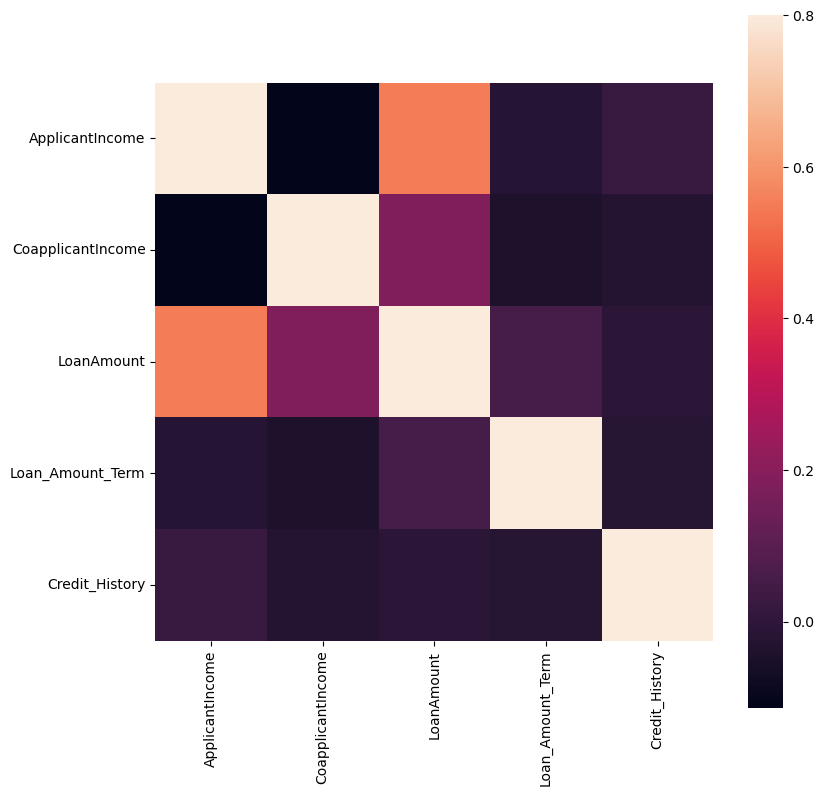

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
corrmat = data.corr(numeric_only=True)
f, ax = plt.subplots(figsize=(9, 9))
sns.heatmap(corrmat, vmax=.8, square=True)

In [14]:
data['Gender'] = data['Gender'].map({'Male': 1, 'Female': 0})
data['Gender'].value_counts()

Gender
1.0    775
0.0    182
Name: count, dtype: int64

<Axes: >

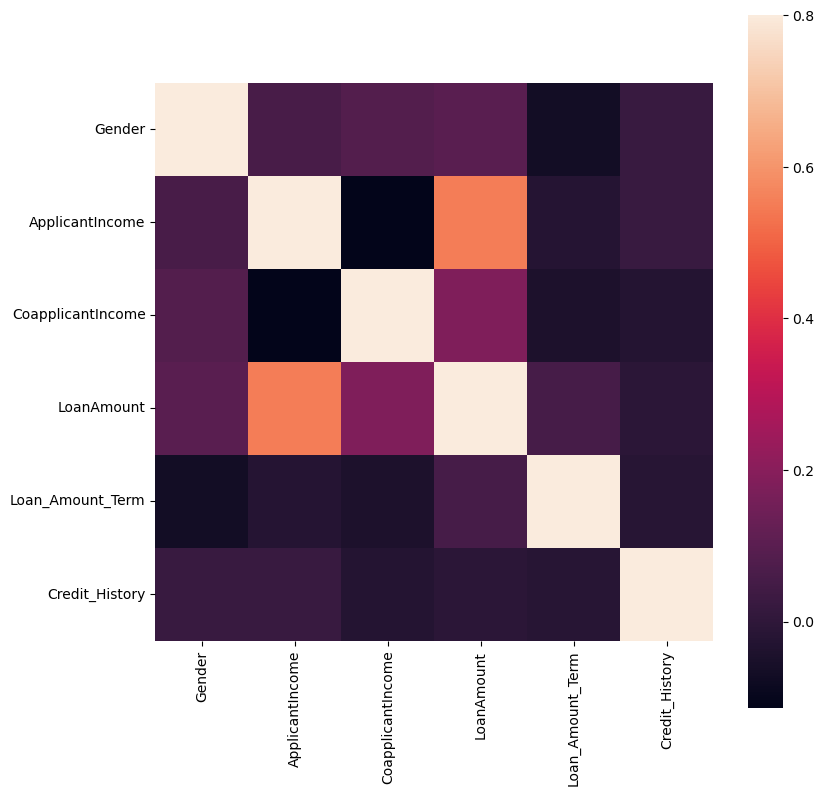

In [15]:
corrmat = data.corr(numeric_only=True)
f, ax = plt.subplots(figsize=(9, 9))
sns.heatmap(corrmat, vmax=.8, square=True)

In [16]:
data['Married'] = data['Married'].map({'Yes': 1, 'No': 0})

In [17]:
data['Married'].value_counts()

Married
1.0    631
0.0    347
Name: count, dtype: int64

In [18]:
data['Dependents'] = data['Dependents'].map({'0': 0, '1': 1, '2': 2, '3+': 3})

In [19]:
data['Dependents'].value_counts()

Dependents
0.0    545
1.0    160
2.0    160
3.0     91
Name: count, dtype: int64

<Axes: >

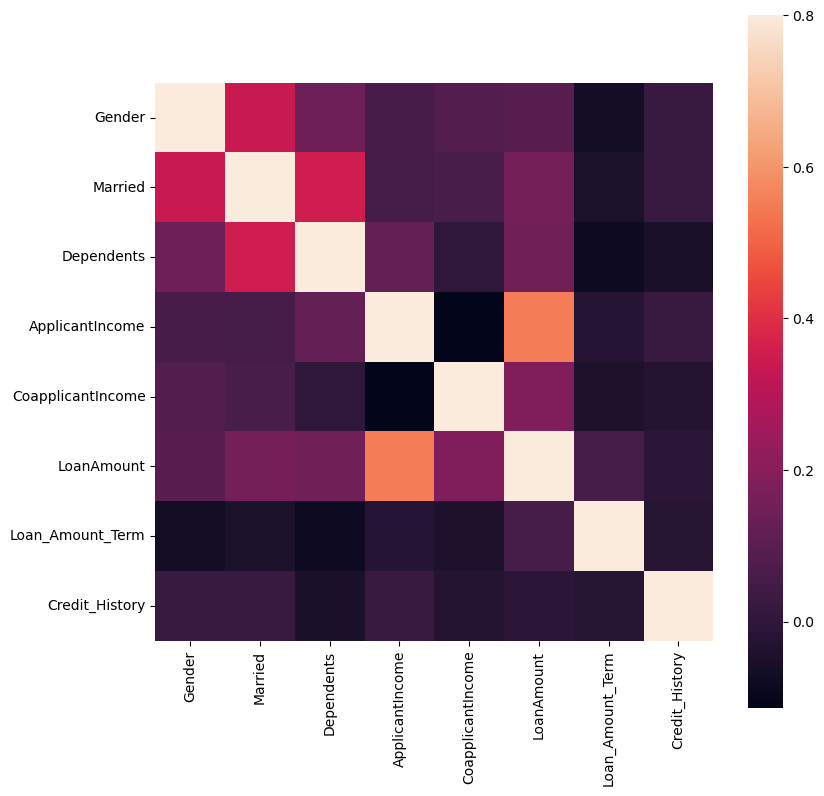

In [20]:
corrmat = data.corr(numeric_only=True)
f, ax = plt.subplots(figsize=(9, 9))
sns.heatmap(corrmat, vmax=.8, square=True)

In [21]:
data['Education'] = data['Education'].map({'Graduate': 1, 'Not Graduate': 0})

In [22]:
data['Education'].value_counts()

Education
1    763
0    218
Name: count, dtype: int64

In [23]:
data['Self_Employed'] = data['Self_Employed'].map({'Yes': 1, 'No': 0})

In [24]:
data['Self_Employed'].value_counts()

Self_Employed
0.0    807
1.0    119
Name: count, dtype: int64

In [25]:
data['Property_Area'].value_counts()

Property_Area
Semiurban    349
Urban        342
Rural        290
Name: count, dtype: int64

In [26]:
data['Property_Area'] = data['Property_Area'].map({'Urban': 2, 'Rural': 0, 'Semiurban': 1})

In [27]:
data['Property_Area'].value_counts()

Property_Area
1    349
2    342
0    290
Name: count, dtype: int64

<Axes: >

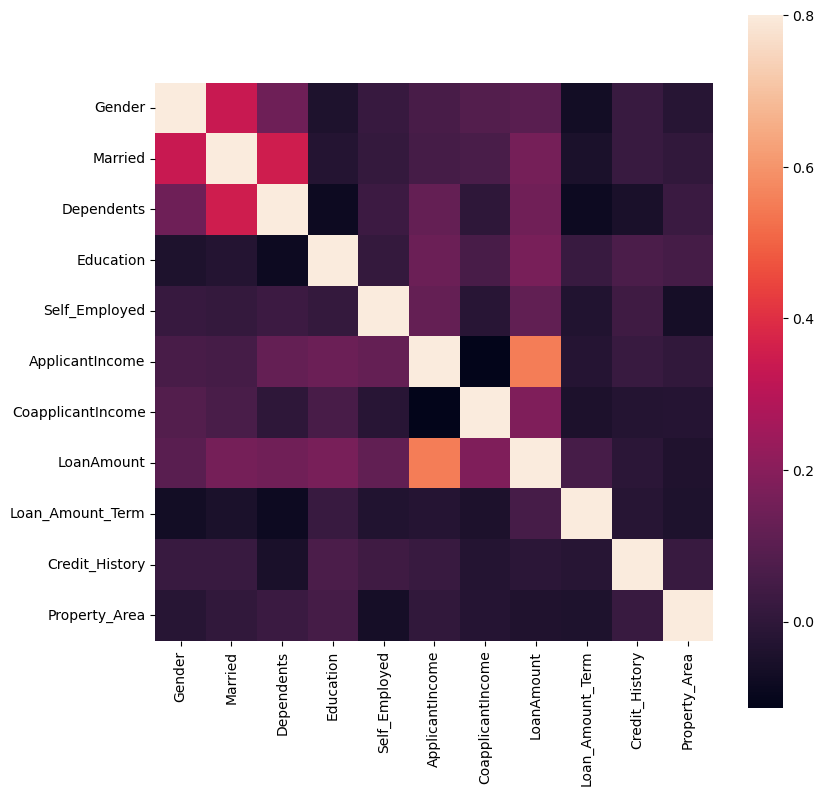

In [28]:
corrmat = data.corr(numeric_only=True)
f, ax = plt.subplots(figsize=(9, 9))
sns.heatmap(corrmat, vmax=.8, square=True)

In [29]:
data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001002,1.0,0.0,0.0,1,0.0,5849,0.0,NaN,360.0,1.0,2
1,LP001003,1.0,1.0,1.0,1,0.0,4583,1508.0,128.0,360.0,1.0,0
2,LP001005,1.0,1.0,0.0,1,1.0,3000,0.0,66.0,360.0,1.0,2
3,LP001006,1.0,1.0,0.0,0,0.0,2583,2358.0,120.0,360.0,1.0,2
4,LP001008,1.0,0.0,0.0,1,0.0,6000,0.0,141.0,360.0,1.0,2


In [30]:
data['Credit_History'].size

981

In [31]:
data['Credit_History'] = data['Credit_History'].fillna(np.random.randint(0, 2))

In [32]:
data.isnull().sum()

Loan_ID               0
Gender               24
Married               3
Dependents           25
Education             0
Self_Employed        55
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           27
Loan_Amount_Term     20
Credit_History        0
Property_Area         0
dtype: int64

In [33]:
data['Married'] = data['Married'].fillna(np.random.randint(0, 2))

In [34]:
data.isnull().sum()

Loan_ID               0
Gender               24
Married               0
Dependents           25
Education             0
Self_Employed        55
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           27
Loan_Amount_Term     20
Credit_History        0
Property_Area         0
dtype: int64

In [35]:
data['LoanAmount'] = data['LoanAmount'].fillna(data['LoanAmount'].median())

In [36]:
data['Loan_Amount_Term'] = data['Loan_Amount_Term'].fillna(data['Loan_Amount_Term'].mean())

In [37]:
data.isnull().sum()

Loan_ID               0
Gender               24
Married               0
Dependents           25
Education             0
Self_Employed        55
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term      0
Credit_History        0
Property_Area         0
dtype: int64

In [38]:
data['Gender'].value_counts()

Gender
1.0    775
0.0    182
Name: count, dtype: int64

In [39]:
data['Gender'] = data['Gender'].fillna(np.random.randint(0, 2))

In [40]:
data['Gender'].value_counts()

Gender
1.0    775
0.0    206
Name: count, dtype: int64

In [41]:
data['Dependents'] = data['Dependents'].fillna(data['Dependents'].median())

In [42]:
data.isnull().sum()

Loan_ID               0
Gender                0
Married               0
Dependents            0
Education             0
Self_Employed        55
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term      0
Credit_History        0
Property_Area         0
dtype: int64

<Axes: >

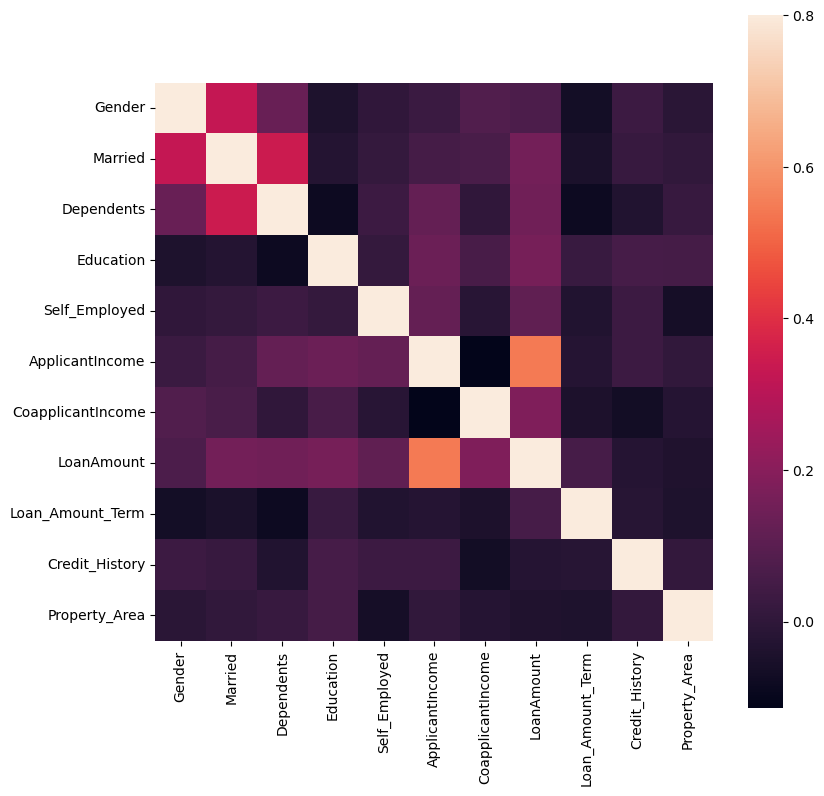

In [43]:
corrmat = data.corr(numeric_only=True)
f, ax = plt.subplots(figsize=(9, 9))
sns.heatmap(corrmat, vmax=.8, square=True)

In [44]:
data['Self_Employed'] = data['Self_Employed'].fillna(np.random.randint(0, 2))

In [45]:
data.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
dtype: int64

In [46]:
data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001002,1.0,0.0,0.0,1,0.0,5849,0.0,126.0,360.0,1.0,2
1,LP001003,1.0,1.0,1.0,1,0.0,4583,1508.0,128.0,360.0,1.0,0
2,LP001005,1.0,1.0,0.0,1,1.0,3000,0.0,66.0,360.0,1.0,2
3,LP001006,1.0,1.0,0.0,0,0.0,2583,2358.0,120.0,360.0,1.0,2
4,LP001008,1.0,0.0,0.0,1,0.0,6000,0.0,141.0,360.0,1.0,2


In [47]:
data.drop(columns=['Loan_ID'], inplace=True)

In [48]:
data.isnull().sum()

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
dtype: int64

In [49]:
train_X = data.iloc[:614, :]
train_y = Loan_status
X_test = data.iloc[614:, :]
seed = 7

In [50]:
from sklearn.model_selection import train_test_split

train_X, test_X, train_y, test_y = train_test_split(train_X, train_y, random_state=seed)

In [51]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

In [52]:
models = []
models.append(("logreg", LogisticRegression(max_iter=1000)))
models.append(("tree", DecisionTreeClassifier()))
models.append(("lda", LinearDiscriminantAnalysis()))
models.append(("svc", SVC()))
models.append(("knn", KNeighborsClassifier()))
models.append(("nb", GaussianNB()))

In [53]:
seed = 7
scoring = 'accuracy'

In [54]:
from sklearn.model_selection import KFold, cross_val_score

result = []
names = []

In [55]:
for name, model in models:
    kfold = KFold(n_splits=10, shuffle=True, random_state=seed)
    cv_result = cross_val_score(model, train_X, train_y, cv=kfold, scoring=scoring)
    result.append(cv_result)
    names.append(name)
    print("%s %f %f" % (name, cv_result.mean(), cv_result.std()))

c:\Users\sabuj\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\sabuj\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_ite

logreg 0.756522 0.080640
tree 0.658696 0.070140
lda 0.760870 0.081340
svc 0.682609 0.083745
knn 0.623913 0.061526
nb 0.717391 0.079578


In [56]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

svc = LogisticRegression(max_iter=1000)
svc.fit(train_X, train_y)
pred = svc.predict(test_X)
print(accuracy_score(test_y, pred))
print(confusion_matrix(test_y, pred))
print(classification_report(test_y, pred))

0.7922077922077922
[[25 23]
 [ 9 97]]
              precision    recall  f1-score   support

           0       0.74      0.52      0.61        48
           1       0.81      0.92      0.86       106

    accuracy                           0.79       154
   macro avg       0.77      0.72      0.73       154
weighted avg       0.79      0.79      0.78       154



c:\Users\sabuj\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [57]:
df_output = pd.DataFrame()

In [58]:
outp = svc.predict(X_test).astype(int)
outp

array([1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1,
       1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1,
       0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0,
       1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [59]:
df_output['Loan_ID'] = Loan_ID
df_output['Loan_Status'] = outp

In [60]:
df_output.head()

,Loan_ID,Loan_Status
0,LP001015,1
1,LP001022,1
2,LP001031,1
3,LP001035,0
4,LP001051,1


In [61]:
df_output[['Loan_ID', 'Loan_Status']].to_csv('output.csv', index=False)